# Lab 1 - Part 2 : Multi-class classification with PyTorch (Predictive Maintenance)

**Goal:** predict the type of failure of a machine (No Failure, Heat Dissipation, Power, Overstrain, Tool Wear, ...)
from its sensor values, using an MLP built with PyTorch.

Dataset: https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification

Steps:
1. Pre-processing (cleaning, encoding, standardization)
2. Exploratory Data Analysis
3. Data augmentation to balance the classes (SMOTE)
4. DNN architecture with PyTorch
5. GridSearch for hyper-parameters
6. Loss / Epochs and Accuracy / Epochs curves
7. Metrics on train and test (accuracy, sensitivity, f1, ...)
8. Regularization and comparison

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from skorch import NeuralNetClassifier

torch.manual_seed(42)
np.random.seed(42)
sns.set_style("whitegrid")

df = pd.read_csv("../dataset/maintenance/predictive_maintenance.csv")
print(df.shape)
df.head()

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 1. Pre-processing

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  str    
dtypes: float64(3), int64(4), str(3)
memory usage: 781.4 KB


In [3]:
print("Missing values:\n", df.isnull().sum())
print("Duplicated rows:", df.duplicated().sum())

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64
Duplicated rows: 0


- `UDI` and `Product ID` are just identifiers -> we drop them.
- `Target` (0/1 failure) and `Failure Type` should say the same thing. Let's check if there are contradictions.

In [4]:
pd.crosstab(df["Failure Type"], df["Target"])

Target,0,1
Failure Type,,
Heat Dissipation Failure,0,112
No Failure,9643,9
Overstrain Failure,0,78
Power Failure,0,95
Random Failures,18,0
Tool Wear Failure,0,45


Some rows are inconsistent:
- `Target = 1` but `Failure Type = No Failure` (we don't know what failure it was)
- `Random Failures` always have `Target = 0`

We remove these rows because the label is not reliable. After that, `Target` is redundant with
`Failure Type` (and would leak the answer), so we drop it too.

In [5]:
bad = ((df["Target"] == 1) & (df["Failure Type"] == "No Failure")) | \
      ((df["Target"] == 0) & (df["Failure Type"] != "No Failure"))
print("Inconsistent rows removed:", bad.sum())
df = df[~bad].drop(columns=["UDI", "Product ID", "Target"]).reset_index(drop=True)

# shorter column names (the brackets are annoying)
df.columns = ["type", "air_temp", "process_temp", "rot_speed", "torque", "tool_wear", "failure_type"]
print(df.shape)
df["failure_type"].value_counts()

Inconsistent rows removed: 27
(9973, 7)


failure_type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64

In [6]:
# feature engineering : two physical features that make sense for the failures
#  - temperature difference (heat dissipation failure happens when it's small)
#  - power = torque * angular speed (power failure happens when it's too low or too high)
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power"] = df["torque"] * df["rot_speed"] * 2 * np.pi / 60

# `type` is a category (L, M, H = low, medium, high quality) -> one hot encoding
df = pd.get_dummies(df, columns=["type"], dtype=float)

# encode the target classes into integers 0..K-1
le = LabelEncoder()
df["label"] = le.fit_transform(df["failure_type"])
classes = list(le.classes_)
print(dict(zip(classes, range(len(classes)))))
df.head()

{'Heat Dissipation Failure': 0, 'No Failure': 1, 'Overstrain Failure': 2, 'Power Failure': 3, 'Tool Wear Failure': 4}


,air_temp,process_temp,rot_speed,torque,tool_wear,failure_type,temp_diff,power,type_H,type_L,type_M,label
0,298.1,308.6,1551,42.8,0,No Failure,10.5,6951.590560,0.0,0.0,1.0,1
1,298.2,308.7,1408,46.3,3,No Failure,10.5,6826.722724,0.0,1.0,0.0,1
2,298.1,308.5,1498,49.4,5,No Failure,10.4,7749.387543,0.0,1.0,0.0,1
3,298.2,308.6,1433,39.5,7,No Failure,10.4,5927.504659,0.0,1.0,0.0,1
4,298.2,308.7,1408,40.0,9,No Failure,10.5,5897.816608,0.0,1.0,0.0,1


## 2. Exploratory Data Analysis

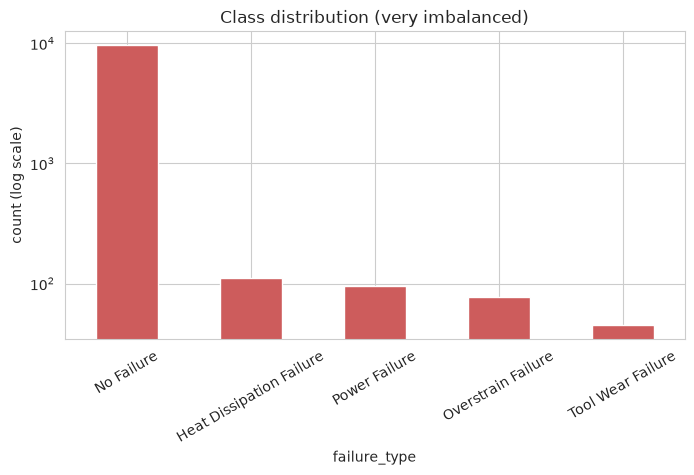

failure_type
No Failure                  96.69
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(8, 4))
df["failure_type"].value_counts().plot(kind="bar", color="indianred")
plt.title("Class distribution (very imbalanced)")
plt.yscale("log")
plt.ylabel("count (log scale)")
plt.xticks(rotation=30)
plt.show()
print((df["failure_type"].value_counts(normalize=True) * 100).round(2))

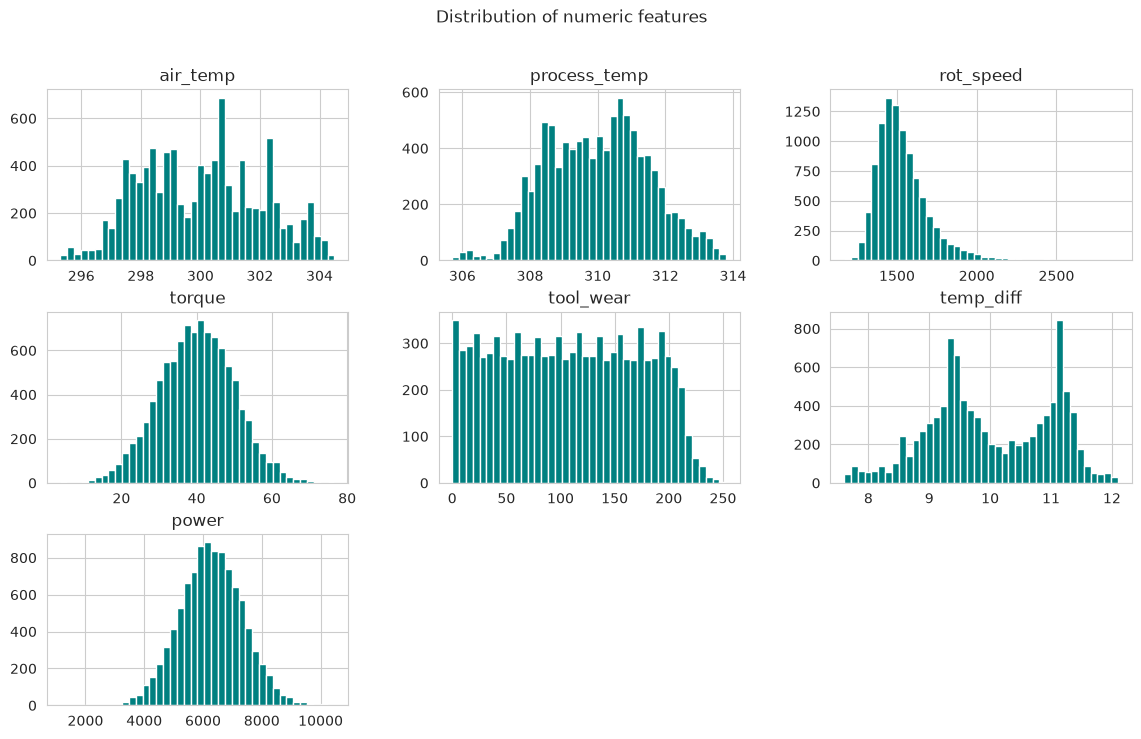

In [8]:
num_cols = ["air_temp", "process_temp", "rot_speed", "torque", "tool_wear", "temp_diff", "power"]
df[num_cols].hist(bins=40, figsize=(14, 8), color="teal")
plt.suptitle("Distribution of numeric features")
plt.show()

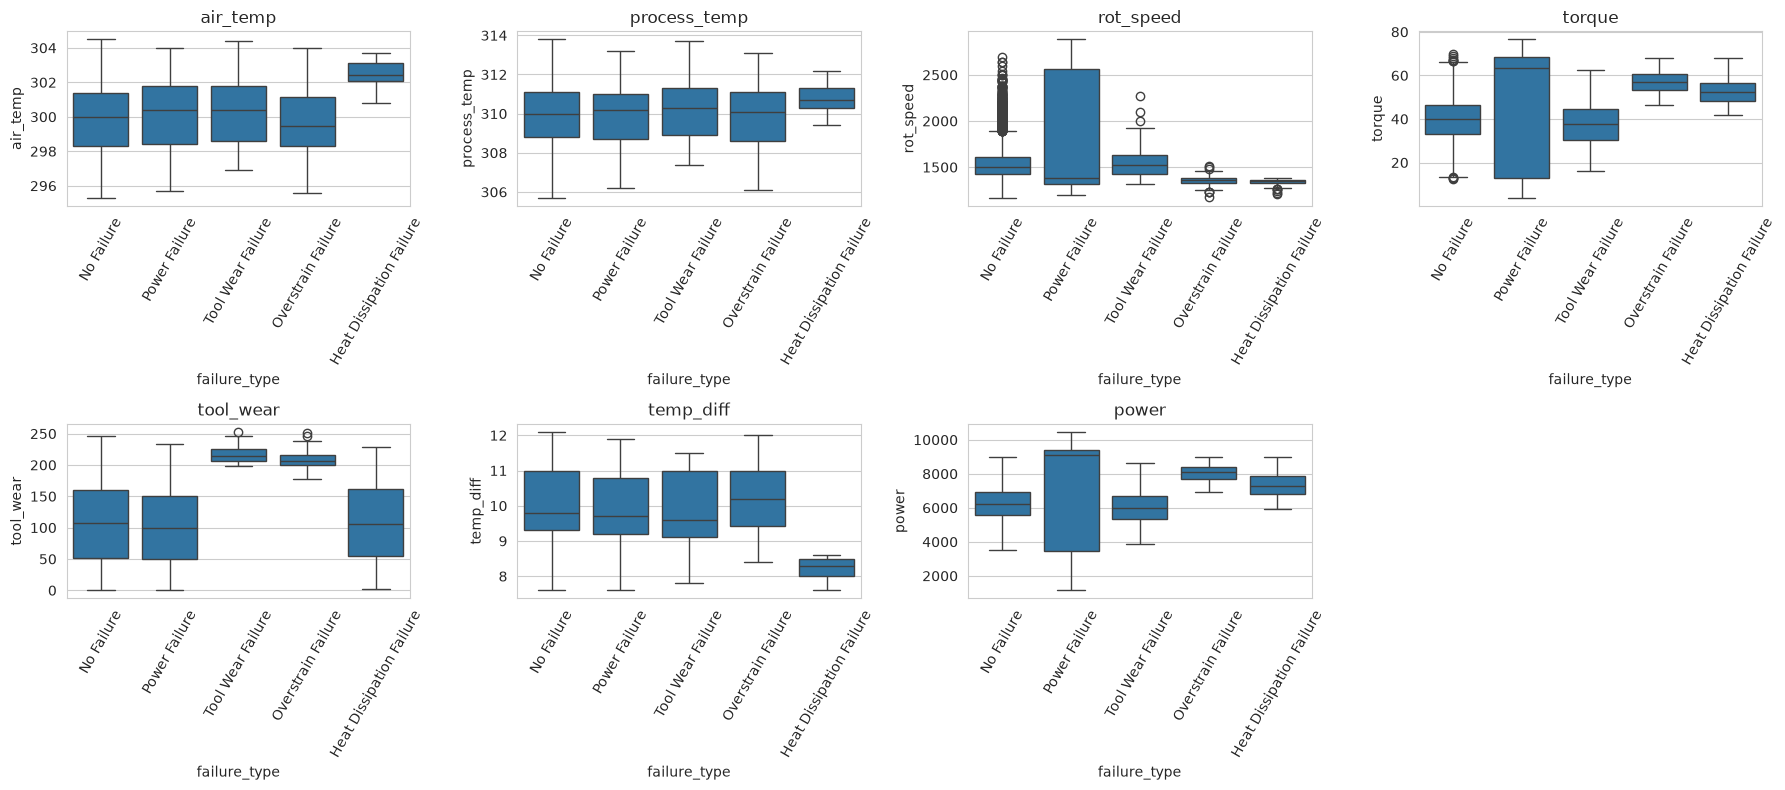

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x="failure_type", y=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=60)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

From the boxplots:
- **Tool Wear Failure** happens when `tool_wear` is high (> 200 min).
- **Heat Dissipation Failure** happens when `temp_diff` is small.
- **Power Failure** happens when `power` is very low or very high.
- **Overstrain Failure** happens with high torque and high tool wear.

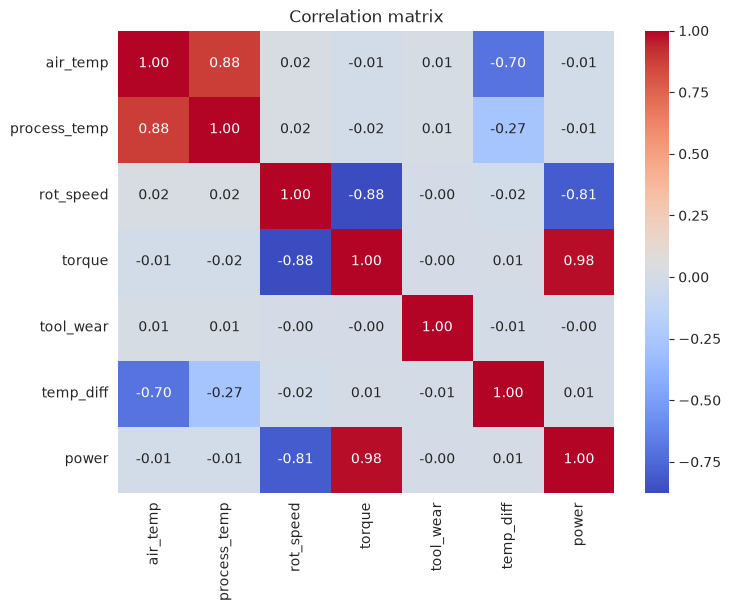

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

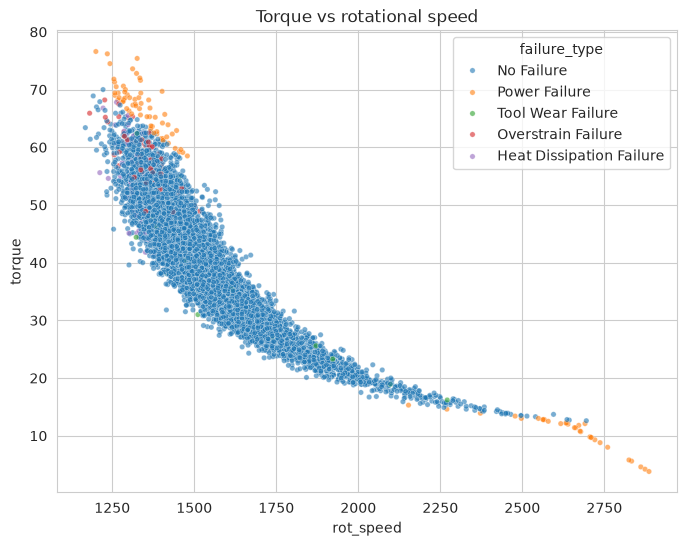

In [11]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="rot_speed", y="torque", hue="failure_type", alpha=0.6, s=15)
plt.title("Torque vs rotational speed")
plt.show()

## Train / test split and standardization

We split **before** any scaling or augmentation (stratified, so each class is in both sets).
The StandardScaler is fitted on the train set only.

In [12]:
feature_cols = [c for c in df.columns if c not in ["failure_type", "label"]]
X = df[feature_cols].values.astype(np.float32)
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)
print(X_train.shape, X_test.shape)

(7978, 10) (1995, 10)


## 3. Data augmentation: SMOTE

The "No Failure" class is ~97% of the data. A model could get 97% accuracy just by always saying "No Failure".
**SMOTE** creates new synthetic samples for the minority classes by interpolating between a sample and its nearest
neighbours of the same class. We apply it on the **train set only** (the test set stays real).

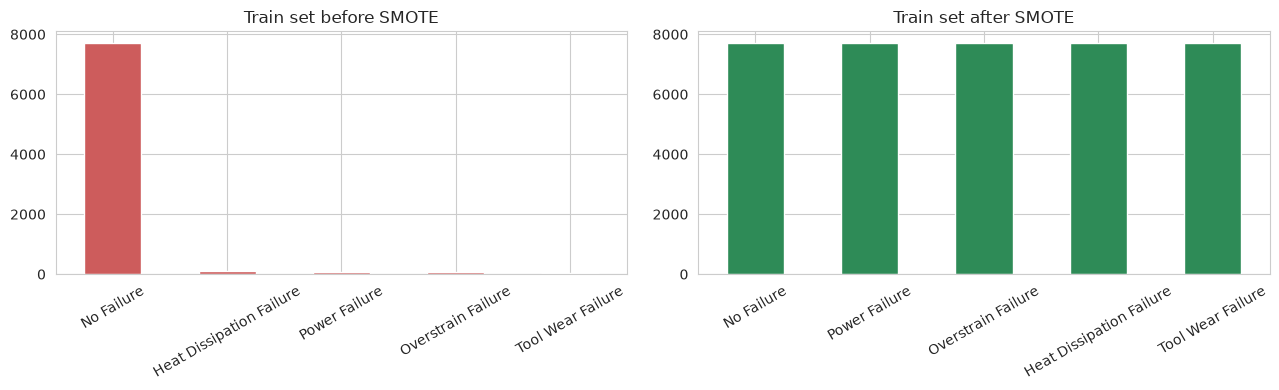

before: (7978, 10)  after: (38570, 10)


In [13]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
X_train_bal = X_train_bal.astype(np.float32)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(y_train).map(dict(enumerate(classes))).value_counts().plot(kind="bar", ax=ax[0], color="indianred")
ax[0].set_title("Train set before SMOTE")
pd.Series(y_train_bal).map(dict(enumerate(classes))).value_counts().plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("Train set after SMOTE")
for a in ax:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("before:", X_train.shape, " after:", X_train_bal.shape)

## 4. DNN architecture

In [14]:
N_FEATURES = X_train.shape[1]
N_CLASSES = len(classes)


class MLPClassifier(nn.Module):
    def __init__(self, n_inputs=N_FEATURES, n_classes=N_CLASSES, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        prev = n_inputs
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))  # logits, softmax is inside CrossEntropyLoss
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


print(MLPClassifier())

MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=5, bias=True)
  )
)


## 5. GridSearch

Same idea as part 1: skorch wraps the PyTorch model so `GridSearchCV` can use it.
We optimize the **macro F1-score** (average of the F1 of each class) because accuracy is misleading with
imbalanced classes.

Note: the grid search is done on the balanced train set. It's a simplification (the validation folds also
contain synthetic samples); a cleaner way would be an imblearn `Pipeline` with SMOTE inside each fold.

In [15]:
net = NeuralNetClassifier(
    MLPClassifier,
    criterion=nn.CrossEntropyLoss,
    batch_size=128,
    train_split=None,
    verbose=0,
)

param_grid = {
    "module__hidden": [(32,), (64, 32), (128, 64, 32)],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "lr": [0.01, 0.001],
    "max_epochs": [30, 60],
}

gs = GridSearchCV(net, param_grid, cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
                  scoring="f1_macro", n_jobs=-1)
gs.fit(X_train_bal, y_train_bal)

print("Best params:", gs.best_params_)
print("Best CV macro F1:", gs.best_score_)

Best params: {'lr': 0.001, 'max_epochs': 60, 'module__hidden': (128, 64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}
Best CV macro F1: 0.9707416574545568


In [16]:
results = pd.DataFrame(gs.cv_results_)
results[["param_module__hidden", "param_optimizer", "param_lr", "param_max_epochs", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(10)

,param_module__hidden,param_optimizer,param_lr,param_max_epochs,mean_test_score
22,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.001,60,0.970742
20,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.001,60,0.951884
18,"(32,)",<class 'torch.optim.adam.Adam'>,0.001,60,0.942654
7,"(32,)",<class 'torch.optim.sgd.SGD'>,0.010,60,0.937476
9,"(64, 32)",<class 'torch.optim.sgd.SGD'>,0.010,60,0.927146
12,"(32,)",<class 'torch.optim.adam.Adam'>,0.001,30,0.914735
1,"(32,)",<class 'torch.optim.sgd.SGD'>,0.010,30,0.911689
11,"(128, 64, 32)",<class 'torch.optim.sgd.SGD'>,0.010,60,0.908491
16,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.001,30,0.900212
14,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.001,30,0.899627


## 6. Training the best model - Loss / Accuracy per epoch

In [17]:
def train_model(model, optimizer, X_train, y_train, X_test, y_test, epochs, batch_size=128, patience=None):
    """Train and record loss + accuracy for train and test at each epoch.
    If patience is given -> early stopping on the test loss."""
    loss_fn = nn.CrossEntropyLoss()
    Xtr, ytr = torch.tensor(X_train), torch.tensor(y_train, dtype=torch.long)
    Xte, yte = torch.tensor(X_test), torch.tensor(y_test, dtype=torch.long)
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    best_loss, best_state, wait = float("inf"), None, 0

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:  # BatchNorm needs at least 2 samples
                continue
            optimizer.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            out_tr, out_te = model(Xtr), model(Xte)
            history["train_loss"].append(loss_fn(out_tr, ytr).item())
            history["test_loss"].append(loss_fn(out_te, yte).item())
            history["train_acc"].append((out_tr.argmax(1) == ytr).float().mean().item())
            history["test_acc"].append((out_te.argmax(1) == yte).float().mean().item())

        if patience is not None:
            if history["test_loss"][-1] < best_loss:
                best_loss, wait = history["test_loss"][-1], 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(history["train_loss"], label="train")
    ax[0].plot(history["test_loss"], label="test")
    ax[0].set_title(f"{title} - Loss / Epochs")
    ax[0].set_xlabel("epoch")
    ax[0].legend()
    ax[1].plot(history["train_acc"], label="train")
    ax[1].plot(history["test_acc"], label="test")
    ax[1].set_title(f"{title} - Accuracy / Epochs")
    ax[1].set_xlabel("epoch")
    ax[1].legend()
    plt.show()

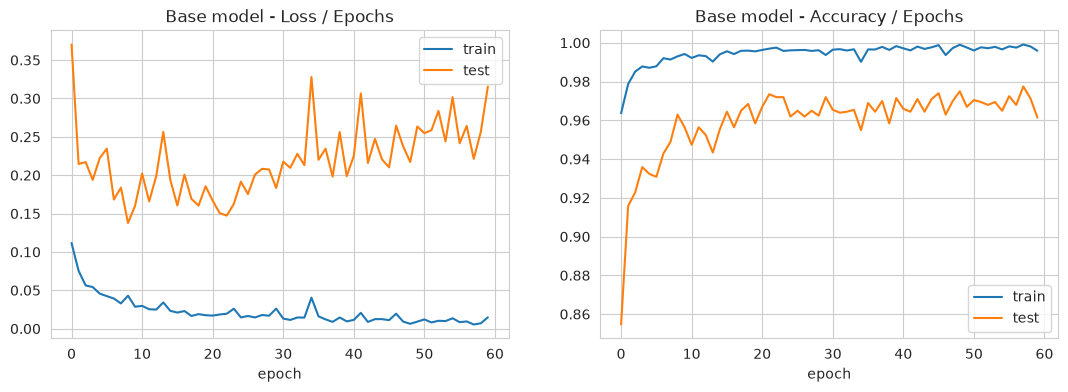

In [18]:
best = gs.best_params_
torch.manual_seed(42)
base_model = MLPClassifier(hidden=best["module__hidden"])
base_opt = best["optimizer"](base_model.parameters(), lr=best["lr"])
hist_base = train_model(base_model, base_opt, X_train_bal, y_train_bal, X_test, y_test, epochs=best["max_epochs"])
plot_history(hist_base, "Base model")

**Interpretation:**
- **Train curves:** the train loss goes down to almost 0 and the train accuracy goes up to almost 100%. The model learns the train set very well.
- **Test loss:** it goes down until around epoch 8, then it goes **up** again (from 0.14 to more than 0.3 at the end). This is **overfitting**: after epoch 8 the model starts to memorize the train data (including the synthetic SMOTE samples) instead of learning general rules.
- **Test accuracy:** it stays around 96-97% even when the test loss goes up. The model still picks the right class most of the time, but it becomes "over-confident" when it is wrong, and that makes the loss bigger.
- Careful: 96% accuracy is not as good as it looks. 97% of the test set is "No Failure", so a model that always says "No Failure" would also get about 97%. That's why we also look at precision, recall and F1 below.

## 7. Metrics on train and test

- **Accuracy**: % of correct predictions
- **Precision**: among the samples predicted as class k, how many are really k
- **Sensitivity (Recall)**: among the real samples of class k, how many we found
- **F1-score**: harmonic mean of precision and recall

We use the **macro** average (each class has the same weight), so the small failure classes count as much
as "No Failure".

In [19]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X)).argmax(1).numpy()


def get_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "sensitivity": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


pred_train = predict(base_model, X_train)   # original (not augmented) train set
pred_test = predict(base_model, X_test)
pd.DataFrame({"train": get_metrics(y_train, pred_train), "test": get_metrics(y_test, pred_test)}).round(4)

,train,test
accuracy,0.9801,0.9614
precision,0.7696,0.6234
sensitivity,0.9959,0.8543
f1,0.8299,0.6949


In [20]:
print(classification_report(y_test, pred_test, target_names=classes, zero_division=0))

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.71      0.91      0.80        22
              No Failure       1.00      0.96      0.98      1929
      Overstrain Failure       0.64      1.00      0.78        16
           Power Failure       0.67      0.84      0.74        19
       Tool Wear Failure       0.10      0.56      0.17         9

                accuracy                           0.96      1995
               macro avg       0.62      0.85      0.69      1995
            weighted avg       0.98      0.96      0.97      1995



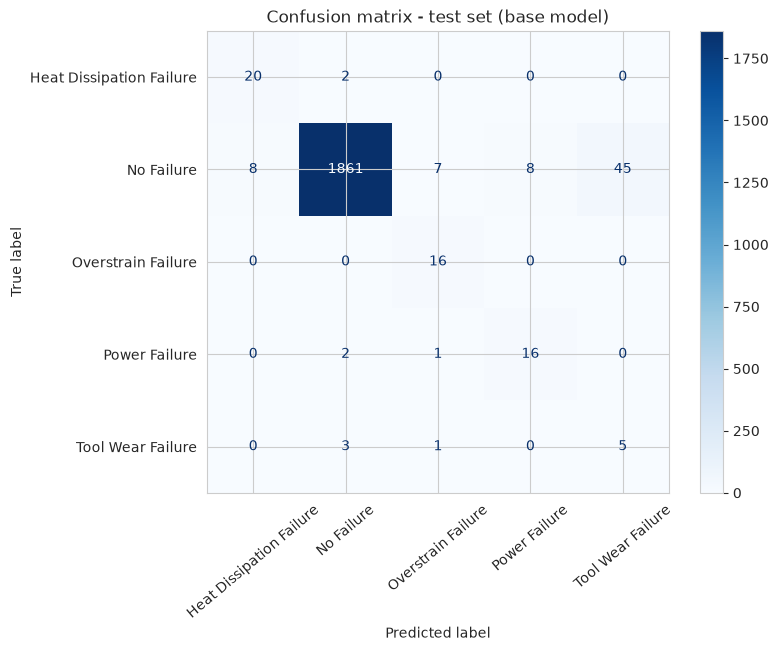

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=classes).plot(ax=ax, cmap="Blues",
                                                                                        xticks_rotation=40)
plt.title("Confusion matrix - test set (base model)")
plt.show()

**What the metrics say:**
- On test, accuracy is 96% but macro F1 is only 0.69. The small failure classes pull the average down.
- **Sensitivity (recall) is good: 0.85.** The model finds most of the real failures (for example 16/16 Overstrain and 20/22 Heat Dissipation).
- **Precision is low: 0.62.** The model gives a lot of false alarms: it predicts a failure for some normal machines (look at the "No Failure" row of the confusion matrix, 45 normal machines are predicted as "Tool Wear Failure").
- **Tool Wear Failure** is the hardest class (F1 = 0.17). It has only 45 real examples in the whole dataset and 9 in the test set, so SMOTE had very few real samples to copy from.
- For maintenance this behaviour is acceptable: it is better to check a machine for nothing than to miss a real failure.
- Train F1 (0.83) is higher than test F1 (0.69), another sign of overfitting.

## 8. Regularization

Same techniques as in part 1: Dropout, L2 weight decay, Batch Normalization, Early stopping, and all combined.

In [22]:
configs = {
    "Dropout":           dict(dropout=0.3, batchnorm=False, wd=0.0, patience=None),
    "L2 (weight decay)": dict(dropout=0.0, batchnorm=False, wd=1e-3, patience=None),
    "BatchNorm":         dict(dropout=0.0, batchnorm=True, wd=0.0, patience=None),
    "Early stopping":    dict(dropout=0.0, batchnorm=False, wd=0.0, patience=5),
    "All combined":      dict(dropout=0.3, batchnorm=True, wd=1e-3, patience=5),
}

histories = {"Base": hist_base}
rows = {"Base": {**{"train_" + k: v for k, v in get_metrics(y_train, pred_train).items()},
                 **{"test_" + k: v for k, v in get_metrics(y_test, pred_test).items()}}}
models = {"Base": base_model}

for name, c in configs.items():
    torch.manual_seed(42)
    m = MLPClassifier(hidden=best["module__hidden"], dropout=c["dropout"], batchnorm=c["batchnorm"])
    opt = best["optimizer"](m.parameters(), lr=best["lr"], weight_decay=c["wd"])
    histories[name] = train_model(m, opt, X_train_bal, y_train_bal, X_test, y_test,
                                  epochs=best["max_epochs"], patience=c["patience"])
    models[name] = m
    rows[name] = {**{"train_" + k: v for k, v in get_metrics(y_train, predict(m, X_train)).items()},
                  **{"test_" + k: v for k, v in get_metrics(y_test, predict(m, X_test)).items()}}

Early stopping at epoch 14
Early stopping at epoch 31


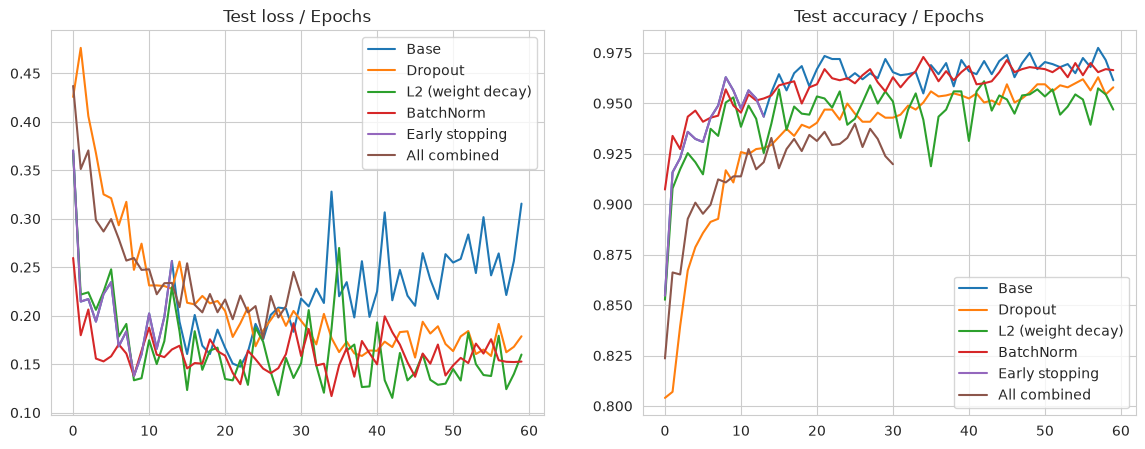

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, h in histories.items():
    ax[0].plot(h["test_loss"], label=name)
    ax[1].plot(h["test_acc"], label=name)
ax[0].set_title("Test loss / Epochs")
ax[1].set_title("Test accuracy / Epochs")
ax[0].legend()
ax[1].legend()
plt.show()

In [24]:
comparison = pd.DataFrame(rows).T.round(4)
comparison

,train_accuracy,train_precision,train_sensitivity,train_f1,test_accuracy,test_precision,test_sensitivity,test_f1
Base,0.9801,0.7696,0.9959,0.8299,0.9614,0.6234,0.8543,0.6949
Dropout,0.9725,0.7040,0.9943,0.7843,0.9579,0.5821,0.8122,0.6574
L2 (weight decay),0.9615,0.6392,0.9920,0.7347,0.9469,0.5636,0.8693,0.6532
BatchNorm,0.9895,0.8386,0.9978,0.8845,0.9664,0.6160,0.7773,0.6751
Early stopping,0.9762,0.6878,0.9873,0.7832,0.9629,0.5827,0.8043,0.6583
All combined,0.9470,0.5966,0.9846,0.6912,0.9398,0.5464,0.8797,0.6401


Best regularized model (test macro F1): BatchNorm


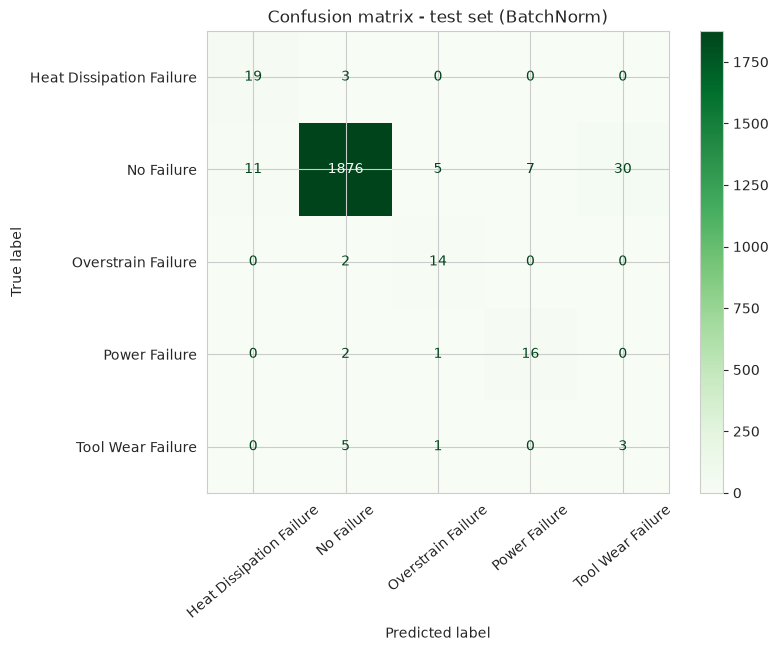

In [25]:
best_reg = comparison["test_f1"].drop("Base").idxmax()
print("Best regularized model (test macro F1):", best_reg)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, predict(models[best_reg], X_test)),
                       display_labels=classes).plot(ax=ax, cmap="Greens", xticks_rotation=40)
plt.title(f"Confusion matrix - test set ({best_reg})")
plt.show()

**Comparison:**
- **Test loss:** all regularization methods fix the overfitting of the base model. Their test loss stays low (around 0.15) while the base model's test loss goes up to 0.32. So the regularized models are more "honest" about their confidence.
- **Test F1:** but none of them gets a better macro F1 than the base model (0.69). BatchNorm is the closest (0.675) and has the best test accuracy (96.6%).
- **Dropout** and **L2** make the training slower and a bit less precise (more false alarms), but L2 finds a bit more failures (recall 0.87 vs 0.85).
- **Early stopping** stops at epoch 14, very close to the epoch where the base test loss was the lowest (around 8). It saves a lot of training time.
- **All combined** stops at epoch 31 and is the weakest (F1 0.64): too much regularization makes the model too simple.
- So the regularization fixed the loss curves, but the real limit of this problem is the very small number of real failure examples, not the model.
- Small note: as in part 1, early stopping watches the test set here. The correct way is to use a separate validation set.